In [ ]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import classification_report, confusion_matrix
from sklearn.model_selection import GroupShuffleSplit

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Bidirectional, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping
import kagglehub
import glob

from sklearn.preprocessing import LabelEncoder
from sklearn.preprocessing import StandardScaler


In [ ]:

# Download latest version
path = kagglehub.dataset_download("uciml/human-activity-recognition-with-smartphones")

print("Path to dataset files:", path)

Using Colab cache for faster access to the 'human-activity-recognition-with-smartphones' dataset.
Path to dataset files: /kaggle/input/human-activity-recognition-with-smartphones


In [ ]:
arquivos_csv = glob.glob(path + "/**/*.csv", recursive=True)

print("Arquivos CSV encontrados:")
for arquivo in arquivos_csv:
    print(arquivo)

Arquivos CSV encontrados:
/kaggle/input/human-activity-recognition-with-smartphones/train.csv
/kaggle/input/human-activity-recognition-with-smartphones/test.csv


In [ ]:
train_path = [f for f in arquivos_csv if "train" in os.path.basename(f).lower()][0]
test_path = [f for f in arquivos_csv if "test" in os.path.basename(f).lower()][0]

df_train = pd.read_csv(train_path)
df_test = pd.read_csv(test_path)

print("Treinamento:", df_train.shape)
print("Teste:", df_test.shape)

display(df_train.head())

Treinamento: (7352, 563)
Teste: (2947, 563)


,tBodyAcc-mean()-X,tBodyAcc-mean()-Y,tBodyAcc-mean()-Z,tBodyAcc-std()-X,tBodyAcc-std()-Y,tBodyAcc-std()-Z,tBodyAcc-mad()-X,tBodyAcc-mad()-Y,tBodyAcc-mad()-Z,tBodyAcc-max()-X,...,fBodyBodyGyroJerkMag-kurtosis(),"angle(tBodyAccMean,gravity)","angle(tBodyAccJerkMean),gravityMean)","angle(tBodyGyroMean,gravityMean)","angle(tBodyGyroJerkMean,gravityMean)","angle(X,gravityMean)","angle(Y,gravityMean)","angle(Z,gravityMean)",subject,Activity
0,0.288585,-0.020294,-0.132905,-0.995279,-0.983111,-0.913526,-0.995112,-0.983185,-0.923527,-0.934724,...,-0.710304,-0.112754,0.030400,-0.464761,-0.018446,-0.841247,0.179941,-0.058627,1,STANDING
1,0.278419,-0.016411,-0.123520,-0.998245,-0.975300,-0.960322,-0.998807,-0.974914,-0.957686,-0.943068,...,-0.861499,0.053477,-0.007435,-0.732626,0.703511,-0.844788,0.180289,-0.054317,1,STANDING
2,0.279653,-0.019467,-0.113462,-0.995380,-0.967187,-0.978944,-0.996520,-0.963668,-0.977469,-0.938692,...,-0.760104,-0.118559,0.177899,0.100699,0.808529,-0.848933,0.180637,-0.049118,1,STANDING
3,0.279174,-0.026201,-0.123283,-0.996091,-0.983403,-0.990675,-0.997099,-0.982750,-0.989302,-0.938692,...,-0.482845,-0.036788,-0.012892,0.640011,-0.485366,-0.848649,0.181935,-0.047663,1,STANDING
4,0.276629,-0.016570,-0.115362,-0.998139,-0.980817,-0.990482,-0.998321,-0.979672,-0.990441,-0.942469,...,-0.699205,0.123320,0.122542,0.693578,-0.615971,-0.847865,0.185151,-0.043892,1,STANDING


In [ ]:
print("Colunas do dataset:")
print(df_train.columns.tolist())

print("\nInformações:")
print(df_train.info())

print("\nDistribuição das atividades:")
print(df_train.iloc[:, -1].value_counts())

Colunas do dataset:
['tBodyAcc-mean()-X', 'tBodyAcc-mean()-Y', 'tBodyAcc-mean()-Z', 'tBodyAcc-std()-X', 'tBodyAcc-std()-Y', 'tBodyAcc-std()-Z', 'tBodyAcc-mad()-X', 'tBodyAcc-mad()-Y', 'tBodyAcc-mad()-Z', 'tBodyAcc-max()-X', 'tBodyAcc-max()-Y', 'tBodyAcc-max()-Z', 'tBodyAcc-min()-X', 'tBodyAcc-min()-Y', 'tBodyAcc-min()-Z', 'tBodyAcc-sma()', 'tBodyAcc-energy()-X', 'tBodyAcc-energy()-Y', 'tBodyAcc-energy()-Z', 'tBodyAcc-iqr()-X', 'tBodyAcc-iqr()-Y', 'tBodyAcc-iqr()-Z', 'tBodyAcc-entropy()-X', 'tBodyAcc-entropy()-Y', 'tBodyAcc-entropy()-Z', 'tBodyAcc-arCoeff()-X,1', 'tBodyAcc-arCoeff()-X,2', 'tBodyAcc-arCoeff()-X,3', 'tBodyAcc-arCoeff()-X,4', 'tBodyAcc-arCoeff()-Y,1', 'tBodyAcc-arCoeff()-Y,2', 'tBodyAcc-arCoeff()-Y,3', 'tBodyAcc-arCoeff()-Y,4', 'tBodyAcc-arCoeff()-Z,1', 'tBodyAcc-arCoeff()-Z,2', 'tBodyAcc-arCoeff()-Z,3', 'tBodyAcc-arCoeff()-Z,4', 'tBodyAcc-correlation()-X,Y', 'tBodyAcc-correlation()-X,Z', 'tBodyAcc-correlation()-Y,Z', 'tGravityAcc-mean()-X', 'tGravityAcc-mean()-Y', 'tGravi

In [ ]:
X_train = df_train.drop(columns=["Activity", "subject"])
y_train = df_train["Activity"]

X_test = df_test.drop(columns=["Activity", "subject"])
y_test = df_test["Activity"]

print("Formato X_train:", X_train.shape)
print("Formato X_test:", X_test.shape)

print("\nClasses:", y_train.unique())

Formato X_train: (7352, 561)
Formato X_test: (2947, 561)

Classes: ['STANDING' 'SITTING' 'LAYING' 'WALKING' 'WALKING_DOWNSTAIRS'
 'WALKING_UPSTAIRS']


In [ ]:

label_encoder = LabelEncoder()

y_train = label_encoder.fit_transform(y_train)
y_test = label_encoder.transform(y_test)

print("Mapeamento das classes:")

for i, classe in enumerate(label_encoder.classes_):
    print(f"{i}: {classe}")

Mapeamento das classes:
0: LAYING
1: SITTING
2: STANDING
3: WALKING
4: WALKING_DOWNSTAIRS
5: WALKING_UPSTAIRS


In [ ]:

scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

In [ ]:

subjects = df_train["subject"].values

splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.20,
    random_state=42
)

idx_train, idx_val = next(
    splitter.split(X_train, y_train, groups=subjects)
)

X_train_final = X_train[idx_train]
y_train_final = y_train[idx_train]

X_val = X_train[idx_val]
y_val = y_train[idx_val]

print("Treinamento:", X_train_final.shape)
print("Validação:", X_val.shape)
print("Teste:", X_test.shape)

Treinamento: (5551, 561)
Validação: (1801, 561)
Teste: (2947, 561)


In [ ]:
TIMESTEPS = 33
N_FEATURES = 17
assert TIMESTEPS * N_FEATURES == X_train_final.shape[1]

X_train_seq = X_train_final.reshape(-1, TIMESTEPS, N_FEATURES)
X_val_seq   = X_val.reshape(-1, TIMESTEPS, N_FEATURES)
X_test_seq  = X_test.reshape(-1, TIMESTEPS, N_FEATURES)

n_classes = len(label_encoder.classes_)

print("Treinamento:", X_train_seq.shape)
print("Validação:  ", X_val_seq.shape)
print("Teste:      ", X_test_seq.shape)
print("Nº de classes:", n_classes)

Treinamento: (5551, 33, 17)
Validação:   (1801, 33, 17)
Teste:       (2947, 33, 17)
Nº de classes: 6


In [ ]:
from tensorflow.keras.optimizers import Adam
import tensorflow as tf
tf.random.set_seed(42)
np.random.seed(42)

model = Sequential([
    Bidirectional(LSTM(64, return_sequences=True), input_shape=(TIMESTEPS, N_FEATURES)),
    Dropout(0.3),
    Bidirectional(LSTM(32)),
    Dropout(0.3),
    Dense(64, activation="relu"),
    Dropout(0.3),
    Dense(n_classes, activation="softmax")
])

model.compile(
    optimizer=Adam(learning_rate=1e-3),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/rnn/bidirectional.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ bidirectional (Bidirectional)   │ (None, 33, 128)        │        41,984 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 33, 128)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional_1 (Bidirectional) │ (None, 64)             │        41,216 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │         4,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 6)              │           390 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 87,750 (342.77 KB)

 Trainable params: 87,750 (342.77 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
early_stop = EarlyStopping(
    monitor="val_loss",
    patience=10,
    restore_best_weights=True,
    verbose=1
)

history = model.fit(
    X_train_seq, y_train_final,
    validation_data=(X_val_seq, y_val),
    epochs=60,
    batch_size=64,
    callbacks=[early_stop],
    verbose=1
)

Epoch 1/60
87/87 ━━━━━━━━━━━━━━━━━━━━ 9s 22ms/step - accuracy: 0.5413 - loss: 1.0258 - val_accuracy: 0.7907 - val_loss: 0.5421
Epoch 2/60
87/87 ━━━━━━━━━━━━━━━━━━━━ 1s 15ms/step - accuracy: 0.8090 - loss: 0.4839 - val_accuracy: 0.8823 - val_loss: 0.3176
Epoch 3/60
87/87 ━━━━━━━━━━━━━━━━━━━━ 1s 15ms/step - accuracy: 0.8662 - loss: 0.3427 - val_accuracy: 0.9012 - val_loss: 0.2836
Epoch 4/60
87/87 ━━━━━━━━━━━━━━━━━━━━ 1s 15ms/step - accuracy: 0.8991 - loss: 0.2605 - val_accuracy: 0.8917 - val_loss: 0.3263
Epoch 5/60
87/87 ━━━━━━━━━━━━━━━━━━━━ 2s 18ms/step - accuracy: 0.9170 - loss: 0.2177 - val_accuracy: 0.9123 - val_loss: 0.2903
Epoch 6/60
87/87 ━━━━━━━━━━━━━━━━━━━━ 2s 22ms/step - accuracy: 0.9274 - loss: 0.1879 - val_accuracy: 0.9062 - val_loss: 0.3444
Epoch 7/60
87/87 ━━━━━━━━━━━━━━━━━━━━ 1s 15ms/step - accuracy: 0.9393 - loss: 0.1657 - val_accuracy: 0.9162 - val_loss: 0.2924
Epoch 8/60
87/87 ━━━━━━━━━━━━━━━━━━━━ 1s 15ms/step - accuracy: 0.9460 - loss: 0.1419 - val_accuracy: 0.9156 - v

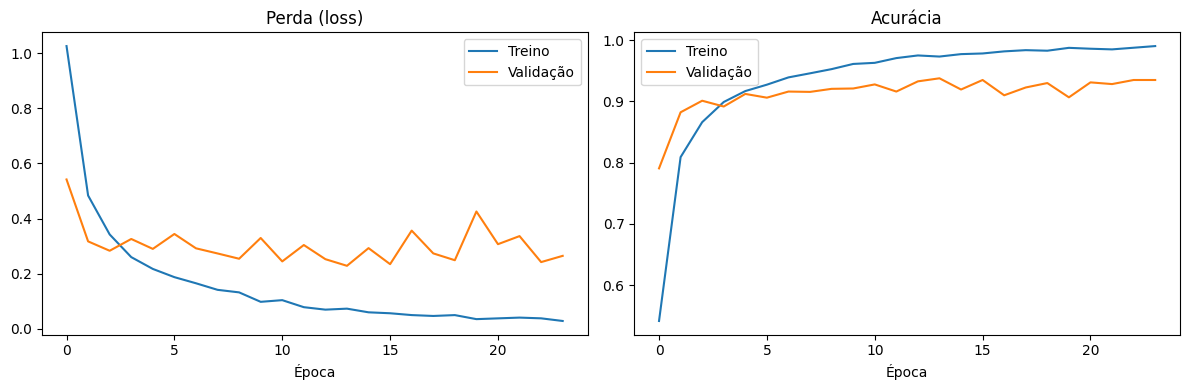

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(history.history["loss"], label="Treino")
axes[0].plot(history.history["val_loss"], label="Validação")
axes[0].set_title("Perda (loss)")
axes[0].set_xlabel("Época")
axes[0].legend()

axes[1].plot(history.history["accuracy"], label="Treino")
axes[1].plot(history.history["val_accuracy"], label="Validação")
axes[1].set_title("Acurácia")
axes[1].set_xlabel("Época")
axes[1].legend()

plt.tight_layout()
plt.show()

In [ ]:
test_loss, test_acc = model.evaluate(X_test_seq, y_test, verbose=0)
print(f"Acurácia no teste: {test_acc:.4f}")
print(f"Loss no teste:     {test_loss:.4f}")

y_pred = np.argmax(model.predict(X_test_seq, verbose=0), axis=1)

print("\nRelatório de classificação:\n")
print(classification_report(y_test, y_pred, target_names=label_encoder.classes_, digits=4))

Acurácia no teste: 0.8941
Loss no teste:     0.4312

Relatório de classificação:

                    precision    recall  f1-score   support

            LAYING     0.9942    0.9516    0.9724       537
           SITTING     0.9336    0.8024    0.8631       491
          STANDING     0.8077    0.9474    0.8720       532
           WALKING     0.8214    0.9456    0.8791       496
WALKING_DOWNSTAIRS     0.9488    0.8833    0.9149       420
  WALKING_UPSTAIRS     0.9082    0.8195    0.8616       471

          accuracy                         0.8941      2947
         macro avg     0.9023    0.8916    0.8938      2947
      weighted avg     0.9011    0.8941    0.8945      2947



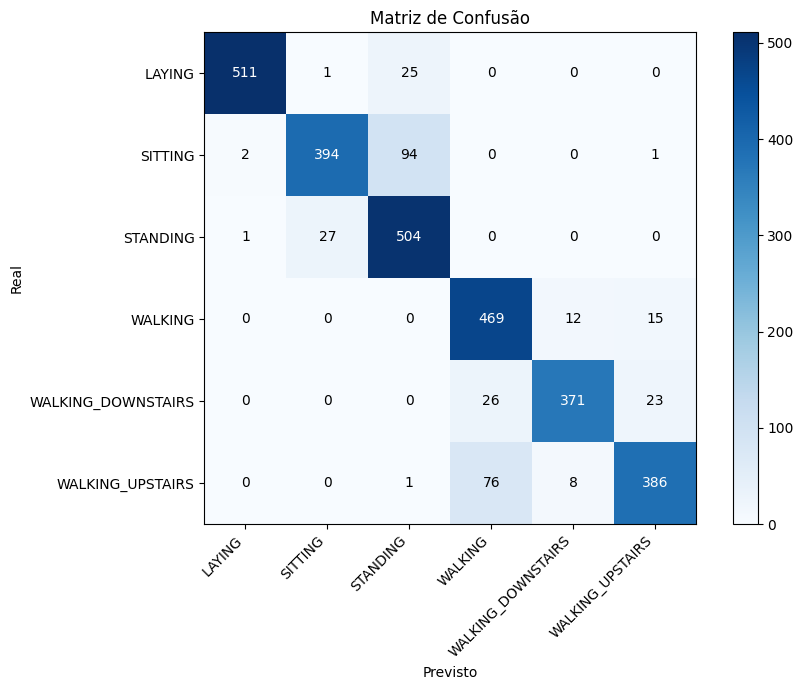

In [ ]:
cm = confusion_matrix(y_test, y_pred)

fig, ax = plt.subplots(figsize=(9, 7))

im = ax.imshow(cm, cmap="Blues")
ax.set_title("Matriz de Confusão")
ax.set_xticks(range(n_classes))
ax.set_yticks(range(n_classes))
ax.set_xticklabels(label_encoder.classes_, rotation=45, ha="right")
ax.set_yticklabels(label_encoder.classes_)
ax.set_xlabel("Previsto")
ax.set_ylabel("Real")

thresh = cm.max() / 2

for i in range(n_classes):
    for j in range(n_classes):
        ax.text(
            j, i, format(cm[i, j], "d"),
            ha="center", va="center",
            color="white" if cm[i, j] > thresh else "black"
        )

fig.colorbar(im, ax=ax, fraction=0.046)
plt.tight_layout()
plt.show()

In [ ]:
erros = []
for i in range(n_classes):
    for j in range(n_classes):
        if i != j and cm[i, j] > 0:
            erros.append((cm[i, j], label_encoder.classes_[i], label_encoder.classes_[j]))

erros.sort(reverse=True)
print("Confusões mais frequentes (real -> previsto):")
for qtd, real, prev in erros[:5]:
    print(f"  {real:20s} -> {prev:20s}: {qtd}")

Confusões mais frequentes (real -> previsto):
  SITTING              -> STANDING            : 94
  WALKING_UPSTAIRS     -> WALKING             : 76
  STANDING             -> SITTING             : 27
  WALKING_DOWNSTAIRS   -> WALKING             : 26
  LAYING               -> STANDING            : 25


In [ ]:
# ## Conclusão
# - Foi treinada uma BiLSTM com os dados originais do dataset Human Activity Recognition with Smartphones (UCI).
# - A validação usou GroupShuffleSplit por sujeito, evitando vazamento entre treino e validação.
# - O conjunto de teste só foi usado na avaliação final.
# - As maiores confusões costumam ocorrer entre atividades parecidas, como SITTING vs STANDING e WALKING_UPSTAIRS vs WALKING_DOWNSTAIRS.

In [ ]:
model.save('human_activity_recognition_model.keras')
print("Modelo salvo com sucesso!")

Modelo salvo com sucesso!


In [ ]:
import shap

amostra = X_test[0]                        # (561,)
referencia = X_train_final.mean(axis=0)    # (561,)

classe_prevista = np.argmax(
    model.predict(amostra.reshape(1, TIMESTEPS, N_FEATURES), verbose=0)
)

def prever_shap(mascaras):
    entradas = np.repeat(
        referencia[np.newaxis, :],
        len(mascaras),
        axis=0
    )

    for i, mascara in enumerate(mascaras):
        grupos_ativos = np.where(mascara > 0.5)[0]
        colunas = np.isin(indice_grupo, grupos_ativos)
        entradas[i, colunas] = amostra[colunas]

    probabilidades = model.predict(
        entradas.reshape(-1, TIMESTEPS, N_FEATURES),
        verbose=0
    )

    return probabilidades[:, classe_prevista]

explainer = shap.KernelExplainer(
    prever_shap,
    np.zeros((1, n_grupos))
)

valores_shap = explainer.shap_values(
    np.ones((1, n_grupos)),
    nsamples=128
)

print("Classe prevista:", atividades[classe_prevista])
print("Formato SHAP:", np.asarray(valores_shap).shape)

  0%|          | 0/1 [00:00<?, ?it/s]

Classe prevista: Em pé
Formato SHAP: (1, 18)


In [ ]:
np.random.seed(42)

indices = np.random.choice(
    len(X_train_seq),
    size=30,
    replace=False
)

background = X_train_seq[indices]
amostras_shap = X_test_seq[:5]

explainer_grad = shap.GradientExplainer(
    model,
    background
)

valores_shap_grad = explainer_grad.shap_values(
    amostras_shap,
    nsamples=100
)

print("Formato Gradient SHAP:", np.asarray(valores_shap_grad).shape)

/usr/local/lib/python3.13/dist-packages/keras/src/models/functional.py:241: UserWarning: The structure of `inputs` doesn't match the expected structure.
Expected: keras_tensor
Received: inputs=['Tensor(shape=(5, 33, 17))']
  warnings.warn(msg)
/usr/local/lib/python3.13/dist-packages/keras/src/models/functional.py:241: UserWarning: The structure of `inputs` doesn't match the expected structure.
Expected: keras_tensor
Received: inputs=['Tensor(shape=(50, 33, 17))']
  warnings.warn(msg)


Formato Gradient SHAP: (5, 33, 17, 6)


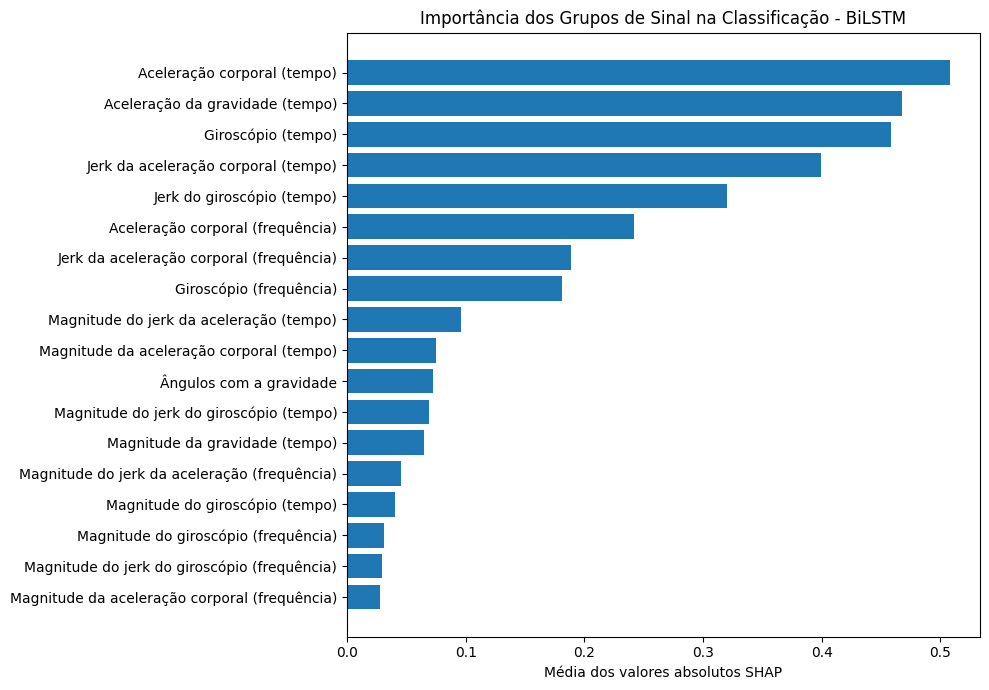

In [ ]:
if isinstance(valores_shap_grad, list):
    valores = np.stack(valores_shap_grad, axis=-1)
else:
    valores = np.asarray(valores_shap_grad)

classes_previstas = np.argmax(
    model.predict(amostras_shap, verbose=0),
    axis=1
)

contribuicoes = np.stack([
    valores[i, :, :, classes_previstas[i]]
    for i in range(len(amostras_shap))
])                                                     # (5, 33, 17)

contribuicoes = contribuicoes.reshape(len(amostras_shap), -1)   # (5, 561)
importancia_features = np.mean(np.abs(contribuicoes), axis=0)   # (561,)

importancia = np.array([
    importancia_features[indice_grupo == g].sum()
    for g in range(n_grupos)
])

ordem = np.argsort(importancia)

plt.figure(figsize=(10, 7))
plt.barh(
    rotulos_grupos[ordem],
    importancia[ordem]
)

plt.xlabel("Média dos valores absolutos SHAP")
plt.title("Importância dos Grupos de Sinal na Classificação - BiLSTM")
plt.tight_layout()
plt.show()

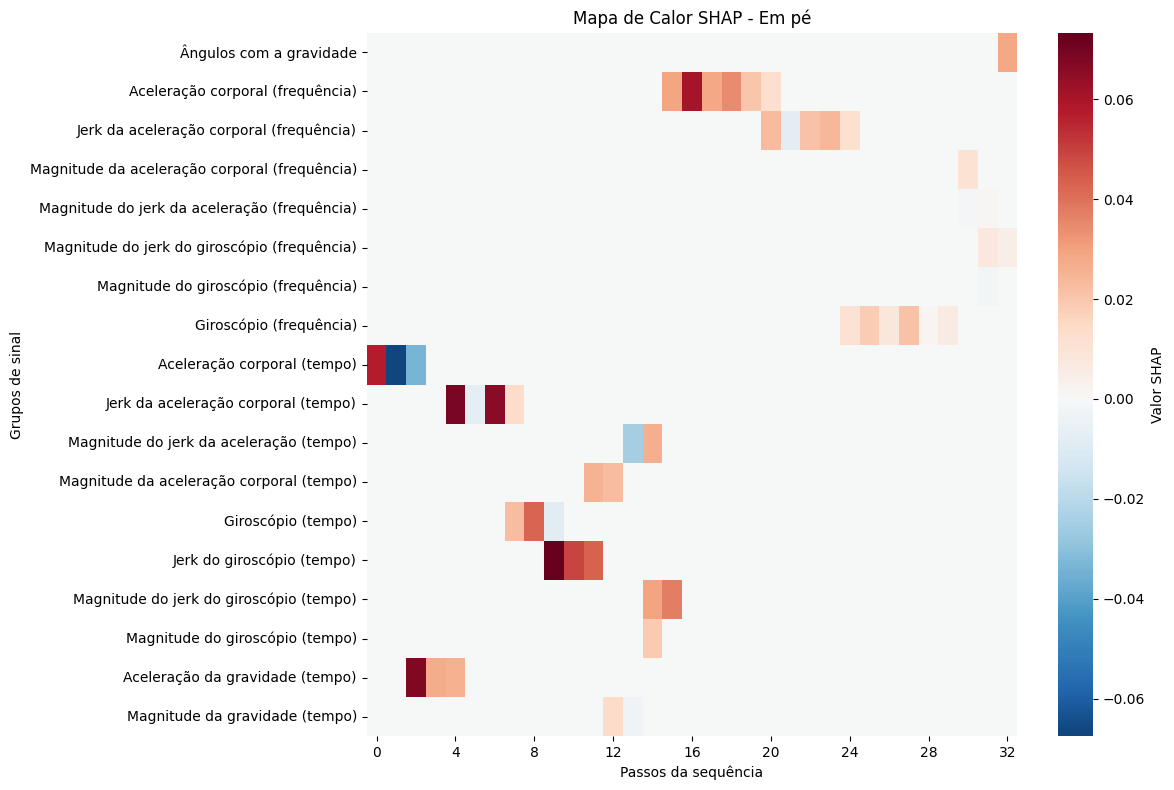

In [ ]:
import seaborn as sns

indice = 0

classe = classes_previstas[indice]
mapa_shap = valores[indice, :, :, classe]              # (33, 17)

# Soma do SHAP de cada grupo de sinal em cada passo
grupos_2d = indice_grupo.reshape(TIMESTEPS, N_FEATURES)   # (33, 17)
mapa_grupos = np.stack([
    np.where(grupos_2d == g, mapa_shap, 0).sum(axis=1)
    for g in range(n_grupos)
])                                                      # (n_grupos, 33)

plt.figure(figsize=(12, 8))

sns.heatmap(
    mapa_grupos,
    cmap="RdBu_r",
    center=0,
    xticklabels=4,
    yticklabels=rotulos_grupos,
    cbar_kws={"label": "Valor SHAP"}
)

plt.title(f"Mapa de Calor SHAP - {atividades[classe]}")
plt.xlabel("Passos da sequência")
plt.ylabel("Grupos de sinal")
plt.tight_layout()
plt.show()